In [1]:
import numpy as np
from scipy.fft import dct, idct
import matplotlib.pyplot as plt
from struct import unpack

In [2]:
f = open("gui.zip", "rb")
lchunk = 0x10000
chunk = f.read(lchunk)
x = unpack("<" + "b" * lchunk, chunk)

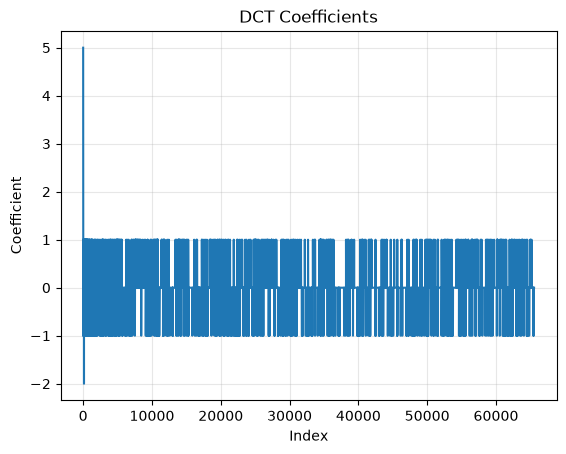

In [3]:
coef = np.rint(dct(x, norm="forward", n=lchunk))
plt.plot(coef)
plt.xlabel("Index")
plt.ylabel("Coefficient")
plt.title("DCT Coefficients")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
reconstructed = np.rint(idct(coef, norm="forward"))
(x != reconstructed).sum()

np.int64(65214)

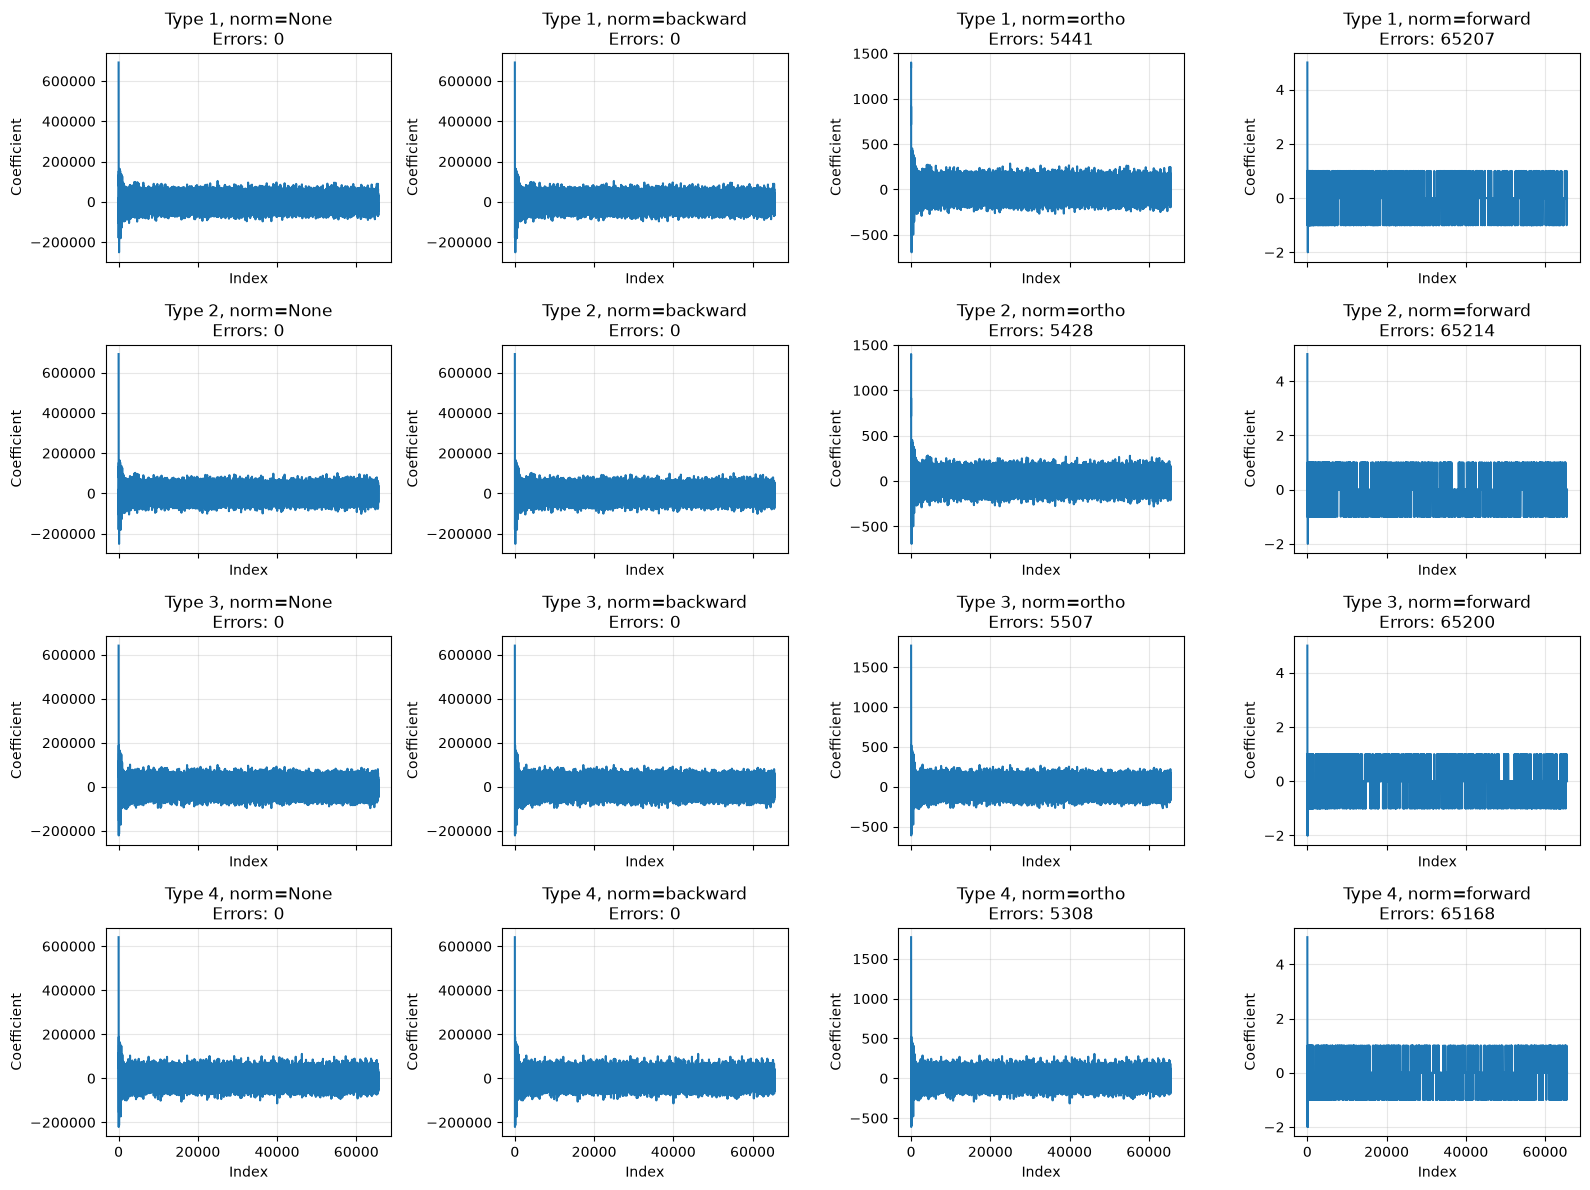

Type 1, norm=None: 0 errors
Type 1, norm=backward: 0 errors
Type 1, norm=ortho: 5441 errors
Type 1, norm=forward: 65207 errors
Type 2, norm=None: 0 errors
Type 2, norm=backward: 0 errors
Type 2, norm=ortho: 5428 errors
Type 2, norm=forward: 65214 errors
Type 3, norm=None: 0 errors
Type 3, norm=backward: 0 errors
Type 3, norm=ortho: 5507 errors
Type 3, norm=forward: 65200 errors
Type 4, norm=None: 0 errors
Type 4, norm=backward: 0 errors
Type 4, norm=ortho: 5308 errors
Type 4, norm=forward: 65168 errors


In [5]:
x_arr = np.asarray(x, dtype=np.float64)
norms = [None, "backward", "ortho", "forward"]
error_counts = {}

fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharex=True)

for row, dct_type in enumerate(range(1, 5)):
    for col, norm in enumerate(norms):
        coefficients = np.rint(dct(x_arr, type=dct_type, norm=norm))
        result = np.rint(idct(coefficients, type=dct_type, norm=norm))
        errors = np.count_nonzero(x_arr != result)
        error_counts[(dct_type, norm)] = errors

        ax = axes[row, col]
        ax.plot(coefficients)
        ax.set_title(f"Type {dct_type}, norm={norm}\nErrors: {errors}")
        ax.set_xlabel("Index")
        ax.set_ylabel("Coefficient")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

for (dct_type, norm), errors in error_counts.items():
    print(f"Type {dct_type}, norm={norm}: {errors} errors")